Original colab : https://colab.research.google.com/drive/1IDS6F8nkfszgqm54EvvnCPaUBXGgsZzf?usp=sharing

# Learning an Image Classification Model from Scratch

* Based on [Deep Learning with Python](https://www.manning.com/books/deep-learning-with-python-second-edition?gclid=CjwKCAjw9aiIBhA1EiwAJ_GTSlKgxc4qopKHPsFWryOoTz7fvhvhzYSjEsgQ-bG1R51QSGppISywpBoClcIQAvD_BwE) by Francois Chollett


### The Fashion MNIST dataset



The [fashion_mnist](https://github.com/zalandoresearch/fashion-mnist) dataset consists of 70,000 images of clothing items across 10 categories.

![Fashion MNIST](https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/doc/img/fashion-mnist-sprite.png)



<br>



In [1]:
import tensorflow as tf
from tensorflow import keras
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# initialize the seeds of different random number generators so that the
# results will be the same every time the notebook is run
keras.utils.set_random_seed(42)

I0000 00:00:1795366399.744456  221990 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795366399.831790  221990 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795366402.630788  221990 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

In [3]:
x_train.shape, y_train.shape

((60000, 28, 28), (60000,))

In [4]:
x_test.shape , y_test.shape

((10000, 28, 28), (10000,))

**What do these numbers mean?**

According to the [Fashion MNIST Github site](https://github.com/zalandoresearch/fashion-mnist#labels), this is what each number 0-9 corresponds to:

| Label  | Description  |
|---|---|
|  0 | T-shirt/top  |
|  1 |  Trouser |
|  2 |   Pullover |
|  3 |  Dress |
|  4 |  Coat |
|  5 |  Sandal |
|  6 |   Shirt |
|  7 |  Sneaker |
|  8 |   Bag |
|  9 |  Ankle boot |

In [5]:
labels = [
    "t-shirt/top",
    "trouser",
    "pullover",
    "dress",
    "coat",
    "sandal",
    "shirt",
    "sneaker",
    "bag",
    "angle boot"
]

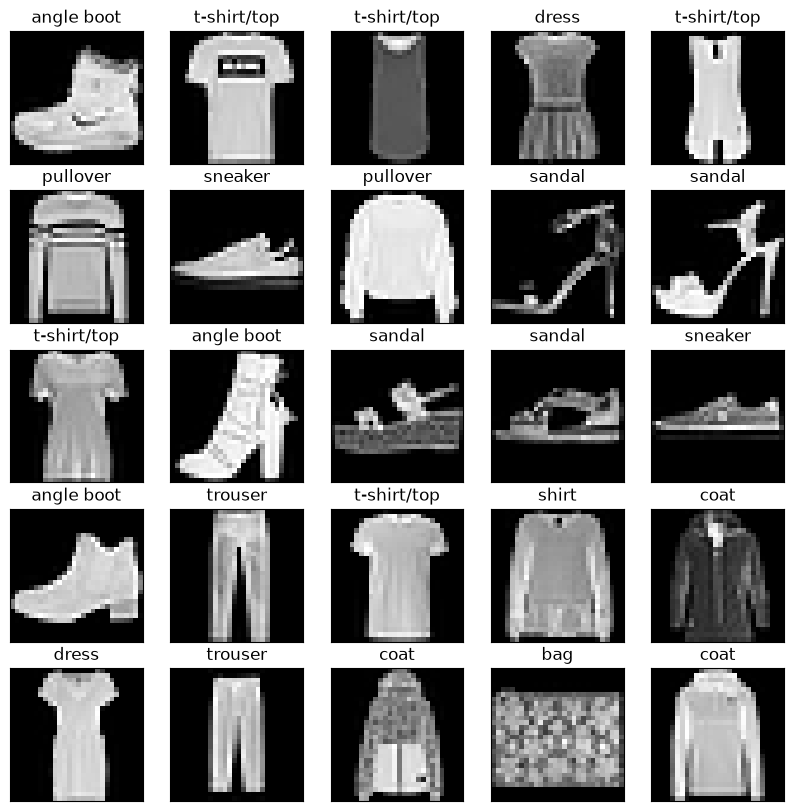

In [6]:
# show 25 images 

fig, ax = plt.subplots(5, 5, figsize=(10, 10))
for i in range(25):
    axc = ax[i//5, i%5]
    axc.imshow(x_train[i], cmap="gray")
    axc.set_title(f"{labels[y_train[i]]}")
    axc.set_xticks([])
    axc.set_yticks([])


## Preprocessing

normalization


In [7]:
x_train = x_train/ 255.0
x_test = x_test/ 255.0

## Build model

In [8]:
# 28*28 vector for each input
input = keras.Input(shape=(28,28))

# transform 28x28 matrix into flattened vector 
input_flattened = keras.layers.Flatten()(input)

h = keras.layers.Dense(256, activation="relu", name="hidden")(input_flattened)

# need softmax because the output is categorical and we need the probabilities to sum up to 1
output = keras.layers.Dense(10, activation="softmax", name="output")(h)

model = keras.Model(input, output)

I0000 00:00:1795366407.362484  221990 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3536 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


In [9]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 28, 28)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden (Dense)                  │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 203,530 (795.04 KB)

 Trainable params: 203,530 (795.04 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:
model.compile(loss="sparse_categorical_crossentropy",
              optimizer="adam",
              metrics=["accuracy"]
              )

In [11]:
batch_size = 64
epochs = 29

history = model.fit(x_train,
                    y_train,
                    batch_size=batch_size,
                    epochs=epochs,
                    validation_split=0.2)

Epoch 1/29


I0000 00:00:1795366410.140717  222258 service.cc:153] XLA service 0x7ec840030d40 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1795366410.140755  222258 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 4050 Laptop GPU, Compute Capability 8.9 (Driver: 13.3.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.28.1)
I0000 00:00:1795366410.158417  222258 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1795366410.262368  222258 cuda_dnn.cc:461] Loaded cuDNN version 92801
I0000 00:00:1795366410.271618  222258 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_919__.12


 35/750 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.6170 - loss: 1.0943

I0000 00:00:1795366413.007005  222258 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


750/750 ━━━━━━━━━━━━━━━━━━━━ 9s 7ms/step - accuracy: 0.8185 - loss: 0.5160 - val_accuracy: 0.8531 - val_loss: 0.4177
Epoch 2/29
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8621 - loss: 0.3846 - val_accuracy: 0.8662 - val_loss: 0.3750
Epoch 3/29
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8781 - loss: 0.3403 - val_accuracy: 0.8737 - val_loss: 0.3545
Epoch 4/29
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8858 - loss: 0.3126 - val_accuracy: 0.8762 - val_loss: 0.3476
Epoch 5/29
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8937 - loss: 0.2905 - val_accuracy: 0.8793 - val_loss: 0.3408
Epoch 6/29
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8991 - loss: 0.2729 - val_accuracy: 0.8810 - val_loss: 0.3362
Epoch 7/29
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9052 - loss: 0.2582 - val_accuracy: 0.8843 - val_loss: 0.3365
Epoch 8/29
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9095 - loss: 0.2454 - val_accuracy: 0.8853 - val_

In [12]:
def plot_loss_curves(history):
  plt.clf()
  history_dict = history.history
  loss_values = history_dict["loss"]
  val_loss_values = history_dict["val_loss"]
  epochs = range(1, len(loss_values) + 1)
  plt.plot(epochs, loss_values, "bo", label="Training loss")
  plt.plot(epochs, val_loss_values, "b", label="Validation loss")
  plt.title("Training and validation loss")
  plt.xlabel("Epochs")
  plt.ylabel("Loss")
  plt.legend()
  plt.show()

In [13]:
def plot_acc_curves(history):
  plt.clf()
  history_dict = history.history
  acc = history_dict["accuracy"]
  val_acc = history_dict["val_accuracy"]
  epochs = range(1, len(acc) + 1)
  plt.plot(epochs, acc, "bo", label="Training acc")
  plt.plot(epochs, val_acc, "b", label="Validation acc")
  plt.title("Training and validation accuracy")
  plt.xlabel("Epochs")
  plt.ylabel("Accuracy")
  plt.legend()
  plt.show()

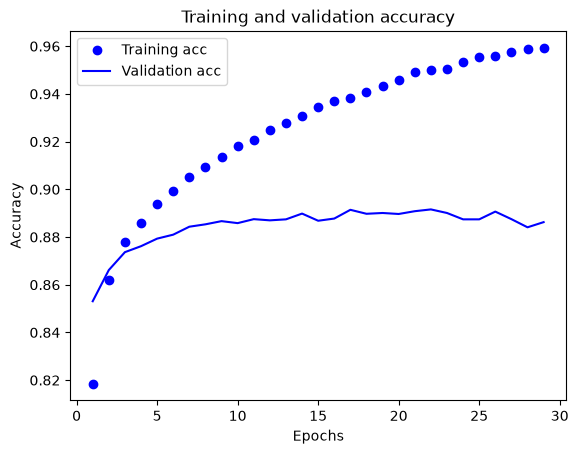

In [14]:
plot_acc_curves(history)

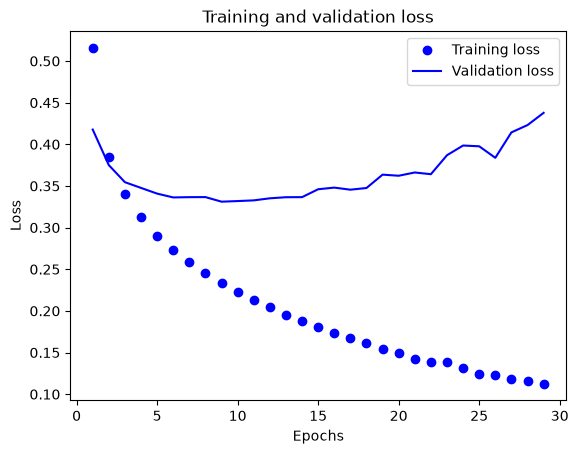

In [15]:
plot_loss_curves(history)

In [16]:
model.evaluate(x_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.8778 - loss: 0.4972


[0.4972347617149353, 0.8777999877929688]

### Adding a second layer

In [31]:
input2 = keras.Input(shape=(28,28))

input_flattened = keras.layers.Flatten()(input2)

h1 = keras.layers.Dense(256, activation="relu", name="first_layer")(input_flattened)

h2 = keras.layers.Dense(256, activation="relu", name="second_layer")(h1)

output2 = keras.layers.Dense(10, activation="softmax", name="Output")(h2)

model2 = keras.Model(input2, output2)

In [32]:
# number of expected parameters
(28*28*256 + 256) + (256*256 + 256) + (10*256 + 10)

269322

In [33]:
model2.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 28, 28)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ first_layer (Dense)             │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ second_layer (Dense)            │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output (Dense)                  │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 269,322 (1.03 MB)

 Trainable params: 269,322 (1.03 MB)

 Non-trainable params: 0 (0.00 B)

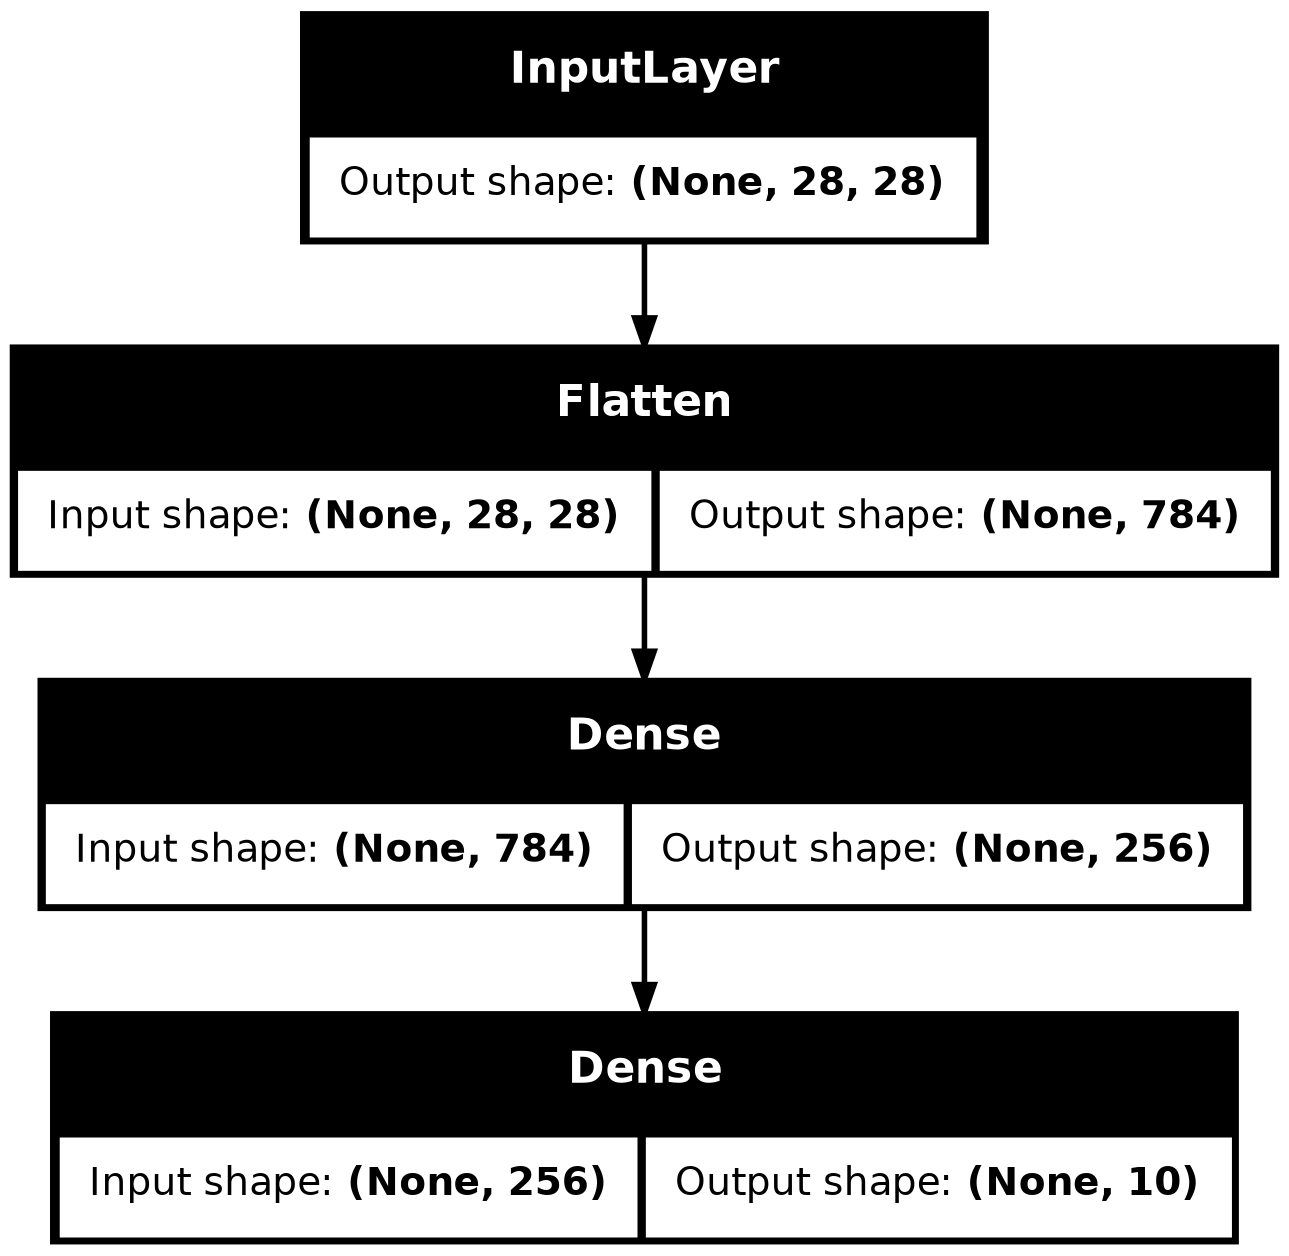

In [34]:
keras.utils.plot_model(model, show_shapes=True)

In [35]:
batch_size2 = 64
epochs2 = 20


model2.compile(loss="sparse_categorical_crossentropy",
              optimizer="adam",
              metrics=["accuracy"])

history2 = model.fit(x_train,
          y_train,
          batch_size=batch_size2,
          epochs=epochs2,
          verbose=1,
          validation_split=0.2
          )

Epoch 1/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9871 - loss: 0.0346 - val_accuracy: 0.8790 - val_loss: 0.9273
Epoch 2/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9857 - loss: 0.0393 - val_accuracy: 0.8799 - val_loss: 0.8872
Epoch 3/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9867 - loss: 0.0362 - val_accuracy: 0.8713 - val_loss: 0.9901
Epoch 4/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9881 - loss: 0.0343 - val_accuracy: 0.8740 - val_loss: 0.9839
Epoch 5/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9869 - loss: 0.0347 - val_accuracy: 0.8742 - val_loss: 1.0177
Epoch 6/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9878 - loss: 0.0327 - val_accuracy: 0.8772 - val_loss: 0.9479
Epoch 7/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9867 - loss: 0.0381 - val_accuracy: 0.8806 - val_loss: 0.9298
Epoch 8/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9877 - loss: 0.0347 - val_accuracy: 0.

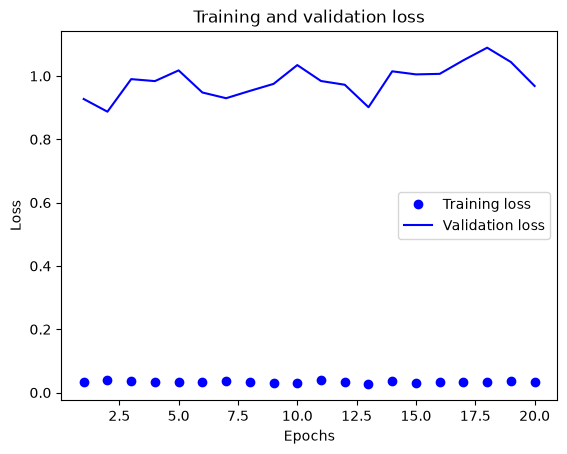

In [36]:
plot_loss_curves(history2)

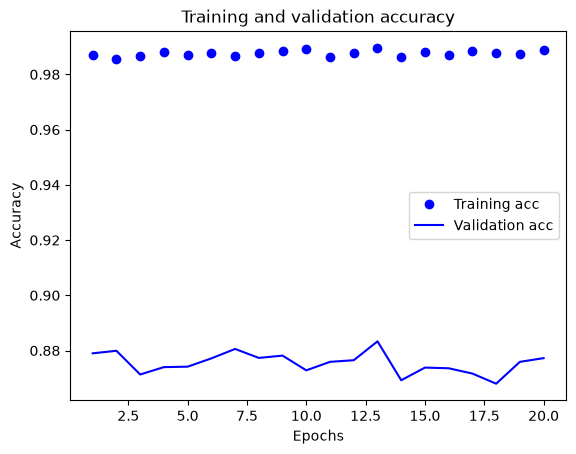

In [37]:
plot_acc_curves(history2)

In [39]:
model2.evaluate(x_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8758 - loss: 0.3952


[0.39521709084510803, 0.8758000135421753]